# Rotation sandbox 3

In [1]:
import sys
sys.path.insert(0, "../")

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as colors
from matplotlib import ticker
from math import pi
from decimal import Decimal
from mosh_src.plotting_functions import *

In [3]:
# Set parameters for all plots in notebook
file = "/Users/seanmullane/Desktop/Research_2023/August_outputs/Results_08_11_1.0cmHL/2rod_14oclock_1e7_85bins_1.0cmHL.csv"
z_slice = 25
norm_point = (0.0, 0.3)
bins = 85
dose_grid_half = 1.0
lattice = dose_grid_half*2/bins
print(lattice)
source_transZ = -0.5
source_plane = cm_to_voxel(np.array(source_transZ), bins, dose_grid_half*2/bins)
applicator_rad = 0.3

source_rad = [0.03, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]
rngX = (-1.0, 1.0)
rngY = (-1.0, 1.0)

0.023529411764705882


In [4]:
norm_energy, __ = extract_norm_energy(file, source_plane, 2, norm_point, bins, lattice)

In [5]:
X, Y, energy, __ = contour_energy(file, (bins, bins), dose_grid_half, source_plane, 2, rngX, rngY, source_rad=source_rad[4], 
                                               scale=True, norm_energy=norm_energy, zero_source=True, std_dev=False)

In [6]:
def twoD_rot(theta: float) -> np.ndarray:
    return np.array([[np.cos(theta), -1*np.sin(theta)], [np.sin(theta), np.cos(theta)]])

def rot_mapping(holding: set, rot_voxel: tuple, debug) -> tuple:
    # is rot_voxel in holding?
    # no ---> new voxel = rot_voxel
    # yes --> check rot_voxel[0] + 1, rot_voxel[0] - 1, etc. until empty voxel found
    # return empty voxel for assignment
    
    if not (rot_voxel in holding):
        empty_vox = rot_voxel

    # Check along x +/- 1, y +/- 1
    elif not ((rot_voxel[0] + 1, rot_voxel[1]) in holding):
        empty_vox = (rot_voxel[0] + 1, rot_voxel[1])

    elif not ((rot_voxel[0], rot_voxel[1] - 1) in holding):
        empty_vox = (rot_voxel[0], rot_voxel[1] - 1)

    elif not ((rot_voxel[0] - 1, rot_voxel[1]) in holding):
        empty_vox = (rot_voxel[0] - 1, rot_voxel[1])

    elif not ((rot_voxel[0], rot_voxel[1] + 1) in holding):
        empty_vox = (rot_voxel[0], rot_voxel[1] + 1)

    # Check four corners
    elif not ((rot_voxel[0] + 1, rot_voxel[1] + 1) in holding):
        empty_vox = (rot_voxel[0] + 1, rot_voxel[1] + 1)

    elif not ((rot_voxel[0] + 1, rot_voxel[1] - 1) in holding):
        empty_vox = (rot_voxel[0] + 1, rot_voxel[1] - 1)

    elif not ((rot_voxel[0] - 1, rot_voxel[1] - 1) in holding):
        empty_vox = (rot_voxel[0] - 1, rot_voxel[1] - 1)

    elif not ((rot_voxel[0] - 1, rot_voxel[1] + 1) in holding):
        empty_vox = (rot_voxel[0] - 1, rot_voxel[1] + 1)

    else:
        raise ValueError("No empty voxel found for " + str(rot_voxel))
        empty_vox = rot_voxel
        debug.append(empty_vox)

    return empty_vox

In [7]:
theta = 0
rot = twoD_rot(theta)

In [8]:
# Rotation algorithm
rotation = np.zeros(np.shape(energy))
holding = set()
debug = []

for i in np.arange(0, np.shape(X)[0]):
    for j in np.arange(0, np.shape(Y)[0]):
        vector = np.array([X[i], Y[j]])

        if np.linalg.norm(vector) <= dose_grid_half - lattice:
            height = energy[i][j]

            rotated_vec = rot @ vector

            rotated_voxel = cm_to_voxel(rotated_vec, bins, lattice)

            # Note that we convert rotated_voxel to a tuple
            rotated_voxel = rot_mapping(holding, (rotated_voxel[0], rotated_voxel[1]), debug)

            rotation[rotated_voxel[0]][rotated_voxel[1]] = height

            holding.add((rotated_voxel[0], rotated_voxel[1]))

print(len(debug))

0


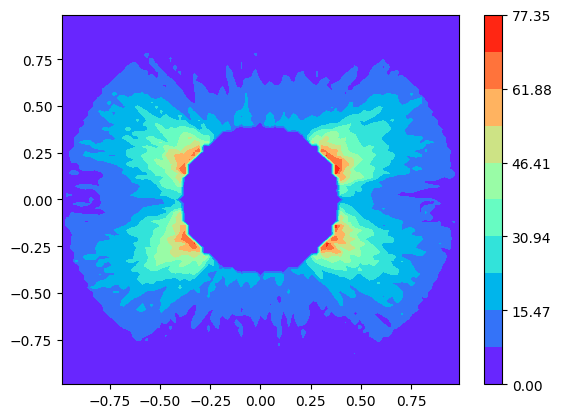

In [9]:
fig1, ax1 = plt.subplots()
contour1 = ax1.contourf(X, Y, rotation, locator=ticker.LinearLocator(), norm="linear", cmap="rainbow")
cbar1 = fig1.colorbar(contour1)